# Wannier functions with the symmetry of the crystal

Do the Wannier functions of a crystal have its symmetry? Not always. The spread
$\Omega$ is minimised one step at a time, and the minimum it reaches depends on the
start. A minimum can break the symmetry a little, and then the tight-binding model
from it breaks it too. Here we impose the symmetry from the start, as the
`site_symmetry` of Wannier90 does (Sakuma, PRB 87, 235109 (2013)).

The constraint is on the rotation $U(\mathbf k)$ of the Bloch states. For every
operation $g$ of the space group:

$$
U(g\mathbf k) = d(g, \mathbf k)\, U(\mathbf k)\, D(g, \mathbf k)^\dagger .
$$

Here $d$ says how the Bloch states at $\mathbf k$ go into the states at
$g\mathbf k$, and $D$ says how the trial orbitals go into each other. So the
Wannier functions transform as the trial orbitals do. Only the irreducible
k-points are free, and the rest of the mesh follows from them.

We take silicon with the cell of notebook 58.

In [1]:
import numpy as np
from defuqumat import Calculator

si = Calculator.from_keywords(
    lattice='fcc', a=5.3976, atoms=[('Si', (0, 0, 0)), ('Si', (0.25, 0.25, 0.25))],
    pseudos={'Si': 'Si.pz-vbc.UPF'}, pseudo_dir='../tests/data/pseudo',
    ecut=272.1, kmesh=(8, 8, 8))
si.get_scf(conv_thr=1e-10)

<SCFResult: converged in 8 iterations, E = -15.84742472 Ry, accuracy = 1.5e-13 Ry, HOMO = 6.2469 eV>

We take twelve bands to eight functions, with an outer window up to 17 eV, as in
notebook 58. There is no frozen window here. The symmetric mode does not allow one,
in this code as in Wannier90. We compare two sets of trial orbitals. `Si:sp3` puts
the same four lobes on both atoms. The second set turns the axes of the second atom,
so both atoms start alike. We run each set with and without `symmetry=True`:

In [2]:
windows = dict(num_bands=12, divisions=(4, 4, 4), dis_win=(None, 17.0),
               engine_options=dict(num_iter=200, conv_window=3))
sets = {'Si:sp3': ['Si:sp3'],
        'turned': ['f=0,0,0:sp3', 'f=0.25,0.25,0.25:sp3:z=0,0,1:x=0,1,0']}
runs = {}
for name, projections in sets.items():
    for symmetry in (False, True):
        w = si.get_wannier(8, projections, symmetry=symmetry, **windows)
        runs[name, symmetry] = w
        print(f'{name:7s} symmetry={symmetry!s:5s} operations {w.nsym:2d}  '
              f'Omega = {w.spread_terms_angstrom2()["omega_total"]:.5f} A^2  spreads',
              np.round(w.spreads_angstrom2, 4))

Si:sp3  symmetry=False operations  1  Omega = 15.76758 A^2  spreads [1.7158 1.7158 1.7158 1.7158 2.2261 2.2261 2.2261 2.2261]


Si:sp3  symmetry=True  operations 48  Omega = 15.77369 A^2  spreads [1.7243 1.7243 1.7243 1.7243 2.2191 2.2191 2.2191 2.2191]


turned  symmetry=False operations  1  Omega = 13.78719 A^2  spreads [1.7234 1.7234 1.7234 1.7234 1.7234 1.7234 1.7234 1.7234]


turned  symmetry=True  operations 48  Omega = 13.78719 A^2  spreads [1.7234 1.7234 1.7234 1.7234 1.7234 1.7234 1.7234 1.7234]


The 48 operations of the diamond group are imposed. Half of them carry a
fractional translation, so they exchange the two atoms.

With `Si:sp3` the two atoms give two groups of spreads, with and without symmetry.
This is not an error. An operation that exchanges the atoms turns a lobe along
$(1,1,1)$ into a lobe along $(-1,-1,-1)$, and that lobe is not in the set on the
other atom. So $D$ mixes the four hybrids, and the two atoms are not equivalent
for this set of trial orbitals. With symmetry $\Omega$ goes up a little, from
15.7676 to 15.7737 Å$^2$. So the free minimum is not symmetric, and the
constraint moves it to the nearest symmetric point. With the turned set the eight
spreads are equal both ways, and $\Omega$ is the same to $10^{-5}$ Å$^2$.

How do we see the broken symmetry in the model? The bands at $\mathbf k$ and at
$g\mathbf k$ must be the same. We interpolate them at a k-point off the mesh and at
its 48 images:

In [3]:
k = np.array([[0.1, 0.2, 0.3]])
group = si.system.symmetry_group(nosym=False)
images = np.vstack([k] + [k @ np.asarray(r).T for r in group.rotations])
for (name, symmetry), w in runs.items():
    e = np.sort(w.bands_ev(images), axis=1)
    print(f'{name:7s} symmetry={symmetry!s:5s}  max change over the images: '
          f'{np.abs(e - e[0]).max():.1e} eV,  max |Im H(R)| {np.abs(w.hoppings.imag).max() * 13.6057:.1e} eV')

Si:sp3  symmetry=False  max change over the images: 3.3e-07 eV,  max |Im H(R)| 2.5e-07 eV
Si:sp3  symmetry=True   max change over the images: 5.2e-13 eV,  max |Im H(R)| 7.4e-09 eV
turned  symmetry=False  max change over the images: 1.9e-08 eV,  max |Im H(R)| 1.7e-08 eV
turned  symmetry=True   max change over the images: 6.6e-13 eV,  max |Im H(R)| 4.5e-10 eV


Without symmetry the bands of `Si:sp3` change between equivalent k-points. With
symmetry the change is at the level of round-off. For the turned set the free
minimum is already symmetric to high accuracy, and the constraint makes it exact.
The Hamiltonian $H_{mn}(\mathbf R)$ follows the same rule, because it is built
from the same rotations.

The figure shows the eight spreads of each run:

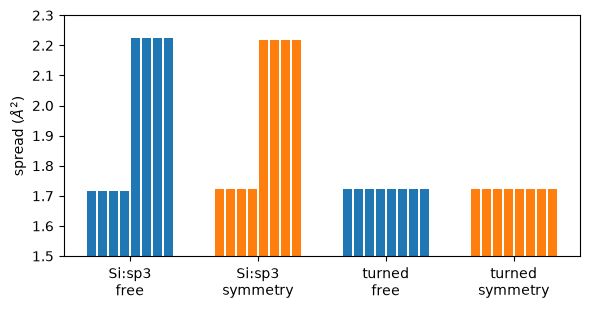

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3.2))
labels = []
for i, ((name, symmetry), w) in enumerate(runs.items()):
    x = i + np.linspace(-0.3, 0.3, 8)
    ax.bar(x, w.spreads_angstrom2, width=0.07, color='C1' if symmetry else 'C0')
    labels.append(f'{name}\n' + ('symmetry' if symmetry else 'free'))
ax.set_xticks(range(len(labels)), labels)
ax.set_ylabel(r'spread ($\AA^2$)')
ax.set_ylim(1.5, 2.3)
fig.tight_layout()

Each group of bars is one run, and each bar one Wannier function. The orbitals on
the two atoms differ for `Si:sp3` in both runs, because that set is not symmetric.
The turned set gives eight equal functions. The symmetric mode does not change what
the trial orbitals mean, so you still choose them. It only makes sure that the
result keeps the symmetry the trial orbitals have. Time reversal is not imposed. On this cell
the imaginary part of $H_{mn}(\mathbf R)$, printed above, is small anyway.

As a reference we ran the same calculation through `pw.x`, `pw2wannier90.x` with
`write_dmn` and `wannier90.x` with `site_symmetry`, on the silicon cell of the
Quantum ESPRESSO test suite with the same windows:

| trial orbitals | Quantum ESPRESSO and Wannier90 (Å$^2$) | this code (Å$^2$) |
|---|---|---|
| `Si:sp3` | 15.773697207 | 15.773696950 |
| turned axes | 13.787202895 | 13.787202775 |

The tests of the symmetric mode are in `tests/unit/test_wannier_sitesym.py`.